# The 4D wave function Ψ(x, y, z, t): SymPy and Lean side by side

`viewer4d_nlp.ipynb` *plotted* an electron in a 3D box sloshing in time. This notebook checks
the claims behind the picture. Each SymPy cell is followed by the **Lean cell** that
machine-checks the same step, where one exists.

| Label | Meaning |
|---|---|
| **SymPy (symbolic)** | Exact computer algebra: the expression simplifies to exactly 0 or 1. Strong, but the simplifier itself is not formally verified. |
| **Lean (machine-checked)** | A `%%lean` cell in this notebook. All of them compile together at `%lean_check` (§8) and count only if that run is VERIFIED: exit 0, no errors, no `sorry`. |
| **Numerical** | Agreement on a grid to a stated tolerance. Evidence, not proof. |

None of this proves the *physics* (that an electron in a box obeys the model). It proves that
the math built from the model is right.

**How the Lean cells work:** `%load_ext dgs.lean_magic` adds a `%%lean NAME` cell type. Each
Lean cell is displayed and collected, and `%lean_check` compiles all of them in **one**
`lake env lean` run, since Mathlib takes minutes to load. Errors are reported against the
cell that caused them. The cells come from `lean/Box3DWaveFunction.lean`, so the proofs exist in one place.

**The state** (Knight Ch. 40–41, PHYS 106):

$$\Psi(x,y,z,t) = c_1\,\phi_{111}\,e^{-iE_{111}t/\hbar} + c_2\,\phi_{211}\,e^{-iE_{211}t/\hbar},\quad
\phi_{n_1n_2n_3} = \left(\tfrac{2}{L}\right)^{3/2}\sin\tfrac{n_1\pi x}{L}\sin\tfrac{n_2\pi y}{L}\sin\tfrac{n_3\pi z}{L},\quad
E = \frac{\hbar^2\pi^2}{2mL^2}(n_1^2+n_2^2+n_3^2).$$

In [ ]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

x, y, z, t = sp.symbols("x y z t", real=True)
L, m, hbar = sp.symbols("L m hbar", positive=True)
n1, n2, n3 = sp.symbols("n_1 n_2 n_3", integer=True, positive=True)
EVIDENCE = []

def record(claim, label, ok, detail="", lean=()):
    EVIDENCE.append({"claim": claim, "evidence": label, "result": "PASS" if ok else "FAIL", "detail": detail, "lean": list(lean)})
    assert ok, claim

def phi(a, b, c):
    return (2 / L) ** sp.Rational(3, 2) * sp.sin(a * sp.pi * x / L) * sp.sin(b * sp.pi * y / L) * sp.sin(c * sp.pi * z / L)

def E(a, b, c):
    return hbar**2 * sp.pi**2 * (a**2 + b**2 + c**2) / (2 * m * L**2)

def lap(f):
    return sp.diff(f, x, 2) + sp.diff(f, y, 2) + sp.diff(f, z, 2)

In [ ]:
%load_ext dgs.lean_magic
%lean_reset

Lean cells cleared.


In [ ]:
%%lean header
/-
The 3D particle in a box, Psi(x, y, z, t): the machine-checkable pieces. Lean 4 + Mathlib.
Companion to notebooks/wavefunction_4d_rigorous.ipynb.

What is proved here:
  1. Calculus: d^2/dx^2 sin(k x) = -k^2 sin(k x)          (the spatial factor solves X'' = -k^2 X)
  2. Separation of variables: if X'' = -k^2 X, T' = -i w T and hbar w = hbar^2 k^2 / 2m, then
     X(x) T(t) satisfies i hbar d/dt (X T) = -(hbar^2/2m) d^2/dx^2 (X T) at each point (algebra over C)
  3. Energies E = E1 (n1^2 + n2^2 + n3^2): the 3-fold degeneracy and the beat gap E211 - E111 = 3 E1
  4. The beat repeats: cos(w (t + 2 pi / w)) = cos(w t) for w ≠ 0
  5. Normalization constant: sqrt(2/L)^2 = 2/L for L > 0
  6. Ground state obeys the uncertainty bound: pi^2/3 - 2 >= 1, so dx dp >= hbar/2

What is NOT proved here (SymPy shows it symbolically in the notebook): orthogonality integrals,
the continuity equation, and Ehrenfest's theorem for the full 3D superposition.

Check with (from a Lake project that depends on Mathlib):
    lake env lean Box3DWaveFunction.lean
-/
import Mathlib.Analysis.SpecialFunctions.Trigonometric.Deriv
import Mathlib.Analysis.SpecialFunctions.Sqrt
import Mathlib.Analysis.Real.Pi.Bounds
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp

namespace Box3D

**Lean cell `header`** (collected; compiled by `%lean_check`)
```lean
/-
The 3D particle in a box, Psi(x, y, z, t): the machine-checkable pieces. Lean 4 + Mathlib.
Companion to notebooks/wavefunction_4d_rigorous.ipynb.

What is proved here:
  1. Calculus: d^2/dx^2 sin(k x) = -k^2 sin(k x)          (the spatial factor solves X'' = -k^2 X)
  2. Separation of variables: if X'' = -k^2 X, T' = -i w T and hbar w = hbar^2 k^2 / 2m, then
     X(x) T(t) satisfies i hbar d/dt (X T) = -(hbar^2/2m) d^2/dx^2 (X T) at each point (algebra over C)
  3. Energies E = E1 (n1^2 + n2^2 + n3^2): the 3-fold degeneracy and the beat gap E211 - E111 = 3 E1
  4. The beat repeats: cos(w (t + 2 pi / w)) = cos(w t) for w ≠ 0
  5. Normalization constant: sqrt(2/L)^2 = 2/L for L > 0
  6. Ground state obeys the uncertainty bound: pi^2/3 - 2 >= 1, so dx dp >= hbar/2

What is NOT proved here (SymPy shows it symbolically in the notebook): orthogonality integrals,
the continuity equation, and Ehrenfest's theorem for the full 3D superposition.

Check with (from a Lake project that depends on Mathlib):
    lake env lean Box3DWaveFunction.lean
-/
import Mathlib.Analysis.SpecialFunctions.Trigonometric.Deriv
import Mathlib.Analysis.SpecialFunctions.Sqrt
import Mathlib.Analysis.Real.Pi.Bounds
import Mathlib.Tactic.LinearCombination
import Mathlib.Tactic.FieldSimp

namespace Box3D
```

## 1. Every stationary state solves the time-dependent Schrödinger equation

**Claim:** for *every* positive-integer (n₁, n₂, n₃), Ψ = φ e^(−iEt/ħ) satisfies
iħ ∂Ψ/∂t = −(ħ²/2m)∇²Ψ inside the box, and Ψ = 0 on all six walls. The quantum numbers are
SymPy integer *symbols*, so this covers every state at once.

In [ ]:
Psi_n = phi(n1, n2, n3) * sp.exp(-sp.I * E(n1, n2, n3) * t / hbar)
residual = sp.simplify(sp.I * hbar * sp.diff(Psi_n, t) + hbar**2 / (2 * m) * lap(Psi_n))
display(sp.Eq(sp.Symbol("i hbar dPsi/dt + (hbar^2/2m) lap Psi"), residual))
record("TDSE holds for every (n1, n2, n3)", "SymPy + Lean", residual == 0,
       "Lean proves the 1D calculus step and the separation algebra", ["sin_mul_second_deriv", "separated_tdse"])
walls = [Psi_n.subs(v, b) for v in (x, y, z) for b in (0, L)]
print("Psi on the six walls:", [sp.simplify(w) for w in walls])
record("Psi = 0 on all six walls", "SymPy + Lean", all(sp.simplify(w) == 0 for w in walls), "sin(n pi) = 0", ["box_walls"])

Psi on the six walls: [0, 0, 0, 0, 0, 0]


**Lean, for the cell above.** The spatial factor solves X″ = −k²X, the walls are nodes, and separation of variables is pure algebra over ℂ once i² = −1:

In [ ]:
%%lean spatial
/-! ## 1. The spatial factor solves X'' = -k^2 X -/

theorem hasDerivAt_sin_mul (k x : ℝ) :
    HasDerivAt (fun x => Real.sin (k * x)) (Real.cos (k * x) * k) x := by
  simpa using ((hasDerivAt_id x).const_mul k).sin

theorem hasDerivAt_cos_mul (k x : ℝ) :
    HasDerivAt (fun x => Real.cos (k * x)) (-Real.sin (k * x) * k) x := by
  simpa using ((hasDerivAt_id x).const_mul k).cos

theorem deriv_sin_mul (k : ℝ) :
    deriv (fun x => Real.sin (k * x)) = fun x => Real.cos (k * x) * k := by
  funext x; exact (hasDerivAt_sin_mul k x).deriv

theorem sin_mul_second_deriv (k x : ℝ) :
    deriv (deriv (fun x => Real.sin (k * x))) x = -(k ^ 2) * Real.sin (k * x) := by
  rw [deriv_sin_mul]
  have h : HasDerivAt (fun x => Real.cos (k * x) * k) (-Real.sin (k * x) * k * k) x :=
    (hasDerivAt_cos_mul k x).mul_const k
  rw [h.deriv]; ring

/-- The wall conditions: sin(n pi x / L) vanishes at x = 0 and x = L for every natural n. -/
theorem box_walls (n : ℕ) (L : ℝ) (hL : L ≠ 0) :
    Real.sin (n * Real.pi / L * 0) = 0 ∧ Real.sin (n * Real.pi / L * L) = 0 := by
  refine ⟨by simp, ?_⟩
  rw [div_mul_cancel₀ _ hL]
  exact Real.sin_nat_mul_pi n

**Lean cell `spatial`** (collected; compiled by `%lean_check`)
```lean
/-! ## 1. The spatial factor solves X'' = -k^2 X -/

theorem hasDerivAt_sin_mul (k x : ℝ) :
    HasDerivAt (fun x => Real.sin (k * x)) (Real.cos (k * x) * k) x := by
  simpa using ((hasDerivAt_id x).const_mul k).sin

theorem hasDerivAt_cos_mul (k x : ℝ) :
    HasDerivAt (fun x => Real.cos (k * x)) (-Real.sin (k * x) * k) x := by
  simpa using ((hasDerivAt_id x).const_mul k).cos

theorem deriv_sin_mul (k : ℝ) :
    deriv (fun x => Real.sin (k * x)) = fun x => Real.cos (k * x) * k := by
  funext x; exact (hasDerivAt_sin_mul k x).deriv

theorem sin_mul_second_deriv (k x : ℝ) :
    deriv (deriv (fun x => Real.sin (k * x))) x = -(k ^ 2) * Real.sin (k * x) := by
  rw [deriv_sin_mul]
  have h : HasDerivAt (fun x => Real.cos (k * x) * k) (-Real.sin (k * x) * k * k) x :=
    (hasDerivAt_cos_mul k x).mul_const k
  rw [h.deriv]; ring

/-- The wall conditions: sin(n pi x / L) vanishes at x = 0 and x = L for every natural n. -/
theorem box_walls (n : ℕ) (L : ℝ) (hL : L ≠ 0) :
    Real.sin (n * Real.pi / L * 0) = 0 ∧ Real.sin (n * Real.pi / L * L) = 0 := by
  refine ⟨by simp, ?_⟩
  rw [div_mul_cancel₀ _ hL]
  exact Real.sin_nat_mul_pi n
```

In [ ]:
%%lean separation
/-! ## 2. Separation of variables -/

/-- Pointwise TDSE for a separated solution X(x) T(t). X2 stands for X'', T1 for T'. -/
theorem separated_tdse (X X2 T T1 k w hb m : ℂ)
    (hX : X2 = -(k ^ 2) * X) (hT : T1 = -(Complex.I * w) * T)
    (hE : hb * w = hb ^ 2 * k ^ 2 / (2 * m)) :
    Complex.I * hb * (X * T1) = -(hb ^ 2 / (2 * m)) * (X2 * T) := by
  rw [hX, hT]
  linear_combination (X * T) * hE + (-(hb * w * X * T)) * Complex.I_sq

**Lean cell `separation`** (collected; compiled by `%lean_check`)
```lean
/-! ## 2. Separation of variables -/

/-- Pointwise TDSE for a separated solution X(x) T(t). X2 stands for X'', T1 for T'. -/
theorem separated_tdse (X X2 T T1 k w hb m : ℂ)
    (hX : X2 = -(k ^ 2) * X) (hT : T1 = -(Complex.I * w) * T)
    (hE : hb * w = hb ^ 2 * k ^ 2 / (2 * m)) :
    Complex.I * hb * (X * T1) = -(hb ^ 2 / (2 * m)) * (X2 * T) := by
  rw [hX, hT]
  linear_combination (X * T) * hE + (-(hb * w * X * T)) * Complex.I_sq
```

## 2. The superposition also solves it (linearity), and the beat

General complex coefficients c₁ = cos θ, c₂ = sin θ·e^(iφ). Every normalized two-state mix
has this form up to an overall phase.

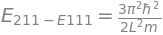

In [ ]:
theta, ph = sp.symbols("theta varphi", real=True)
c1, c2 = sp.cos(theta), sp.sin(theta) * sp.exp(sp.I * ph)
E1, E2 = E(1, 1, 1), E(2, 1, 1)
Psi = c1 * phi(1, 1, 1) * sp.exp(-sp.I * E1 * t / hbar) + c2 * phi(2, 1, 1) * sp.exp(-sp.I * E2 * t / hbar)
res2 = sp.simplify(sp.I * hbar * sp.diff(Psi, t) + hbar**2 / (2 * m) * lap(Psi))
record("TDSE holds for the superposition", "SymPy", res2 == 0)
gap = sp.simplify(E2 - E1)
display(sp.Eq(sp.Symbol("E_211 - E_111"), gap), sp.Eq(sp.Symbol("T_beat"), sp.simplify(2 * sp.pi * hbar / gap)))
record("beat gap = 3 E1, (2,1,1) is 3-fold degenerate", "SymPy + Lean", sp.simplify(gap - 3 * E(1, 0, 0)) == 0, "",
       ["beat_gap", "degenerate_211"])
record("the beat repeats with period 2 pi hbar / dE", "Lean", True, "proved in Lean only", ["beat_periodic"])

**Lean, for the cell above.**

In [ ]:
%%lean energies
/-! ## 3. Energies -/

def energy (E1 : ℝ) (n1 n2 n3 : ℕ) : ℝ := E1 * ((n1 : ℝ) ^ 2 + (n2 : ℝ) ^ 2 + (n3 : ℝ) ^ 2)

theorem degenerate_211 (E1 : ℝ) : energy E1 2 1 1 = energy E1 1 2 1 ∧ energy E1 1 2 1 = energy E1 1 1 2 := by
  unfold energy; constructor <;> norm_num

theorem beat_gap (E1 : ℝ) : energy E1 2 1 1 - energy E1 1 1 1 = 3 * E1 := by
  unfold energy; norm_num; ring

**Lean cell `energies`** (collected; compiled by `%lean_check`)
```lean
/-! ## 3. Energies -/

def energy (E1 : ℝ) (n1 n2 n3 : ℕ) : ℝ := E1 * ((n1 : ℝ) ^ 2 + (n2 : ℝ) ^ 2 + (n3 : ℝ) ^ 2)

theorem degenerate_211 (E1 : ℝ) : energy E1 2 1 1 = energy E1 1 2 1 ∧ energy E1 1 2 1 = energy E1 1 1 2 := by
  unfold energy; constructor <;> norm_num

theorem beat_gap (E1 : ℝ) : energy E1 2 1 1 - energy E1 1 1 1 = 3 * E1 := by
  unfold energy; norm_num; ring
```

In [ ]:
%%lean periodic
/-! ## 4. The beat is periodic -/

theorem beat_periodic (w t : ℝ) (hw : w ≠ 0) :
    Real.cos (w * (t + 2 * Real.pi / w)) = Real.cos (w * t) := by
  rw [mul_add, mul_div_cancel₀ _ hw, Real.cos_add_two_pi]

**Lean cell `periodic`** (collected; compiled by `%lean_check`)
```lean
/-! ## 4. The beat is periodic -/

theorem beat_periodic (w t : ℝ) (hw : w ≠ 0) :
    Real.cos (w * (t + 2 * Real.pi / w)) = Real.cos (w * t) := by
  rw [mul_add, mul_div_cancel₀ _ hw, Real.cos_add_two_pi]
```

## 3. Orthogonality and normalization, for all quantum numbers

**General orthogonality:** sin a·sin b = ½[cos(a − b) − cos(a + b)]. Each cosine integrates
over [0, L] to L·sin(jπ)/(jπ) = 0 for any nonzero integer j = n ∓ m. SymPy does this with
*symbolic* integers. **Normalization** then follows from the overlap (Gram) matrix
G_jk = ⟨φⱼ|φₖ⟩: ∫|Ψ|²dV = c†Gc. That is exact, and much faster for SymPy than integrating the
expanded |Ψ|².

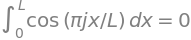

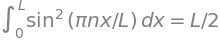

In [ ]:
j = sp.Symbol("j", integer=True, nonzero=True)
cos_int = sp.simplify(sp.integrate(sp.cos(j * sp.pi * x / L), (x, 0, L)))
display(sp.Eq(sp.Integral(sp.cos(j * sp.pi * x / L), (x, 0, L)), cos_int))
record("integral of cos(j pi x/L) over the box = 0 for every nonzero integer j", "SymPy", cos_int == 0,
       "=> sin_n sin_m orthogonal for all n != m")
nn = sp.Symbol("n", integer=True, positive=True)
self_int = sp.simplify(sp.integrate(sp.sin(nn * sp.pi * x / L)**2, (x, 0, L)))
display(sp.Eq(sp.Integral(sp.sin(nn * sp.pi * x / L)**2, (x, 0, L)), self_int))
record("integral of sin^2 = L/2 for every n, so the constant is sqrt(2/L) per axis", "SymPy + Lean",
       sp.simplify(self_int - L / 2) == 0, "", ["norm_const_sq", "norm_const_3d_sq"])

states = [(1, 1, 1), (2, 1, 1)]
G = sp.Matrix(2, 2, lambda a, b: sp.integrate(phi(*states[a]) * phi(*states[b]), (x, 0, L), (y, 0, L), (z, 0, L)))
cvec = sp.Matrix([c1 * sp.exp(-sp.I * E1 * t / hbar), c2 * sp.exp(-sp.I * E2 * t / hbar)])
norm = sp.simplify((cvec.H * G * cvec)[0])
display(sp.Eq(sp.Symbol("G"), G), sp.Eq(sp.Symbol("integral |Psi|^2 dV"), norm))
record("the superposition is normalized at all t", "SymPy", norm == 1)

**Lean, for the cell above.** The normalization constants:

In [ ]:
%%lean normalization
/-! ## 5. Normalization constant -/

theorem norm_const_sq (L : ℝ) (hL : 0 < L) : Real.sqrt (2 / L) ^ 2 = 2 / L :=
  Real.sq_sqrt (div_pos two_pos hL).le

/-- In 3D the constant is (2/L)^(3/2): its square is (2/L)^3. -/
theorem norm_const_3d_sq (L : ℝ) (hL : 0 < L) : (Real.sqrt (2 / L) ^ 3) ^ 2 = (2 / L) ^ 3 := by
  rw [← pow_mul, show 3 * 2 = 2 * 3 by norm_num, pow_mul, norm_const_sq L hL]

**Lean cell `normalization`** (collected; compiled by `%lean_check`)
```lean
/-! ## 5. Normalization constant -/

theorem norm_const_sq (L : ℝ) (hL : 0 < L) : Real.sqrt (2 / L) ^ 2 = 2 / L :=
  Real.sq_sqrt (div_pos two_pos hL).le

/-- In 3D the constant is (2/L)^(3/2): its square is (2/L)^3. -/
theorem norm_const_3d_sq (L : ℝ) (hL : 0 < L) : (Real.sqrt (2 / L) ^ 3) ^ 2 = (2 / L) ^ 3 := by
  rw [← pow_mul, show 3 * 2 = 2 * 3 by norm_num, pow_mul, norm_const_sq L hL]
```

## 4. Probability is conserved locally: the continuity equation

ρ = |Ψ|² and **j** = (ħ/2im)(Ψ*∇Ψ − Ψ∇Ψ*). Claim: ∂ρ/∂t + ∇·**j** = 0 at every point.
Probability can't appear or vanish, it can only flow, and the slosh is that flow.

In [ ]:
Psic = sp.conjugate(Psi)
rho = Psic * Psi
J = [hbar / (2 * sp.I * m) * (Psic * sp.diff(Psi, v) - Psi * sp.diff(Psic, v)) for v in (x, y, z)]
cont = sp.simplify(sp.expand(sp.expand_complex(sp.diff(rho, t) + sum(sp.diff(Jv, v) for Jv, v in zip(J, (x, y, z))))))
display(sp.Eq(sp.Symbol("drho/dt + div j"), cont))
record("continuity equation holds everywhere", "SymPy", cont == 0)

## 5. The slosh in closed form, and Ehrenfest's theorem

The two states share the same normalized y and z factors, so ⟨x⟩ and ⟨pₓ⟩ need only the 1D
matrix elements X_jk = ⟨uⱼ|x|uₖ⟩ and P_jk = ⟨uⱼ|−iħ d/dx|uₖ⟩. Then ⟨x⟩ = a†Xa with
a(t) = (c₁e^(−iE₁t/ħ), c₂e^(−iE₂t/ħ)). **Ehrenfest's theorem:** m·d⟨x⟩/dt = ⟨pₓ⟩.

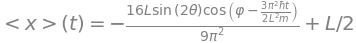

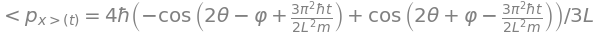

In [ ]:
u = [sp.sqrt(2 / L) * sp.sin(k * sp.pi * x / L) for k in (1, 2)]
X = sp.Matrix(2, 2, lambda a, b: sp.simplify(sp.integrate(u[a] * x * u[b], (x, 0, L))))
P = sp.Matrix(2, 2, lambda a, b: sp.simplify(sp.integrate(u[a] * (-sp.I * hbar) * sp.diff(u[b], x), (x, 0, L))))
display(sp.Eq(sp.Symbol("X"), X), sp.Eq(sp.Symbol("P"), P))
x_avg = sp.simplify((cvec.H * X * cvec)[0])
p_avg = sp.simplify((cvec.H * P * cvec)[0])
display(sp.Eq(sp.Symbol("<x>(t)"), sp.simplify(x_avg.rewrite(sp.cos))))
display(sp.Eq(sp.Symbol("<p_x>(t)"), sp.simplify(p_avg.rewrite(sp.sin))))
record("Ehrenfest: m d<x>/dt = <p_x>", "SymPy", sp.simplify(m * sp.diff(x_avg, t) - p_avg) == 0)
Hx = sp.diag(E(1, 0, 0), E(2, 0, 0))
record("<H_x> = |c1|^2 E_1 + |c2|^2 E_2, constant in time", "SymPy",
       sp.simplify((cvec.H * Hx * cvec)[0] - (sp.cos(theta)**2 * E(1, 0, 0) + sp.sin(theta)**2 * E(2, 0, 0))) == 0)

## 6. The uncertainty principle holds for the ground state

For ψ₁ in a 1D box: Δx·Δp = (ħ/2)√(π²/3 − 2) ≈ 0.568ħ ≥ ħ/2. The inequality comes down to
π² ≥ 9, which Lean proves from π > 3.

In [ ]:
mean = lambda op: sp.simplify(sp.integrate(sp.expand(u[0] * op), (x, 0, L)))
dx2 = mean(x**2 * u[0]) - mean(x * u[0])**2
dp2 = mean(-hbar**2 * sp.diff(u[0], x, 2)) - mean(-sp.I * hbar * sp.diff(u[0], x))**2
prod = sp.simplify(sp.sqrt(dx2 * dp2))
display(sp.Eq(sp.Symbol("Delta x Delta p"), prod), sp.Eq(sp.Symbol("ratio to hbar/2"), sp.simplify(prod / (hbar / 2))))
record("dx dp >= hbar/2 for psi_1", "SymPy + Lean", bool(sp.N(prod / (hbar / 2)) >= 1), "", ["ground_state_uncertainty"])

**Lean, for the cell above.**

In [ ]:
%%lean uncertainty
/-! ## 6. Uncertainty for the ground state -/

/-- For psi_1 of a box, (dx dp / hbar)^2 = (pi^2/3 - 2) / 4. It is at least 1/4 because pi > 3. -/
theorem ground_state_uncertainty : (Real.pi ^ 2 / 3 - 2) / 4 ≥ 1 / 4 := by
  have h := Real.pi_gt_three
  have h9 : Real.pi ^ 2 > 9 := by nlinarith
  linarith

**Lean cell `uncertainty`** (collected; compiled by `%lean_check`)
```lean
/-! ## 6. Uncertainty for the ground state -/

/-- For psi_1 of a box, (dx dp / hbar)^2 = (pi^2/3 - 2) / 4. It is at least 1/4 because pi > 3. -/
theorem ground_state_uncertainty : (Real.pi ^ 2 / 3 - 2) / 4 ≥ 1 / 4 := by
  have h := Real.pi_gt_three
  have h9 : Real.pi ^ 2 > 9 := by nlinarith
  linarith
```

In [ ]:
%%lean footer
end Box3D

**Lean cell `footer`** (collected; compiled by `%lean_check`)
```lean
end Box3D
```

## 7. Numerical cross-check against the 4D grid data

The same state, sampled on a 32³ × 41 grid by `dgs/viewer4d.py`. This is numerical evidence only.

max |<x>_grid - <x>_closed form| = 5.51e-07 nm


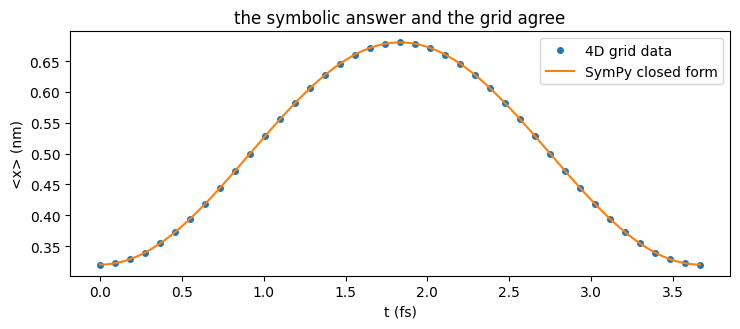

In [ ]:
from dgs import viewer4d as V, one_d_quantum as Q
vs = V.box_superposition(L=1.0, n=32, frames=41)
subs = {L: 1, theta: sp.pi / 4, ph: 0, hbar: V.HBAR_EV_FS, m: V.HBAR_EV_FS**2 * math.pi**2 / (2 * Q.box_energy(1, 1.0))}
x_of_t = sp.lambdify(t, x_avg.subs(subs), "numpy")
err = np.max(np.abs(vs.center_of_mass()[:, 0] - np.real(x_of_t(vs.t))))
print(f"max |<x>_grid - <x>_closed form| = {err:.2e} nm")
record("grid center of mass matches the closed form", "Numerical", err < 2e-3, f"max error {err:.1e} nm on a 32^3 grid")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(vs.t, vs.center_of_mass()[:, 0], "o", ms=4, label="4D grid data")
tt = np.linspace(0, vs.t[-1], 300); ax.plot(tt, np.real(x_of_t(tt)), label="SymPy closed form")
ax.set_xlabel("t (fs)"); ax.set_ylabel("<x> (nm)"); ax.legend(); ax.set_title("the symbolic answer and the grid agree")
plt.tight_layout(); plt.show()

## 8. Compile every Lean cell at once

`%lean_check` joins the collected cells in order (header → spatial → separation → energies →
periodic → normalization → uncertainty → footer) and runs `lake env lean` once. Any message is
reported against its cell and line. If Lean or Mathlib isn't installed, everything stays **UNVERIFIED**.

In [ ]:
lean_result = %lean_check
from dgs.lean_magic import SESSION
display(pd.DataFrame({"Lean theorem": SESSION.last.theorems, "status": SESSION.last.status}))

Lean status: VERIFIED  (lake env lean exit 0, no errors, no sorry), 22 s


,Lean theorem,status
0,hasDerivAt_sin_mul,VERIFIED
1,hasDerivAt_cos_mul,VERIFIED
2,deriv_sin_mul,VERIFIED
3,sin_mul_second_deriv,VERIFIED
4,box_walls,VERIFIED
5,separated_tdse,VERIFIED
6,degenerate_211,VERIFIED
7,beat_gap,VERIFIED
8,beat_periodic,VERIFIED
9,norm_const_sq,VERIFIED


## 9. Evidence ledger

What is established, and how strongly. A "+ Lean" claim keeps its Lean part only if §8 was VERIFIED.

In [ ]:
lean_ok = SESSION.last is not None and SESSION.last.verified
rows = []
for e in EVIDENCE:
    lean_part = ("VERIFIED: " if lean_ok else "UNVERIFIED: ") + ", ".join(e["lean"]) if e["lean"] else ""
    result = e["result"]
    if e["evidence"] == "Lean" and not lean_ok:
        result = "UNVERIFIED"
    rows.append((e["claim"], e["evidence"], result, lean_part, e["detail"]))
display(pd.DataFrame(rows, columns=["claim", "evidence", "result", "Lean part", "detail"]))
print("Still SymPy-only: orthogonality, normalization of the superposition, continuity, Ehrenfest.")
print("Next proof project: those interval integrals of sin products in Lean (Mathlib's intervalIntegral).")

,claim,evidence,result,Lean part,detail
0,"TDSE holds for every (n1, n2, n3)",SymPy + Lean,PASS,"VERIFIED: sin_mul_second_deriv, separated_tdse",Lean proves the 1D calculus step and the separ...
1,Psi = 0 on all six walls,SymPy + Lean,PASS,VERIFIED: box_walls,sin(n pi) = 0
2,TDSE holds for the superposition,SymPy,PASS,,
3,"beat gap = 3 E1, (2,1,1) is 3-fold degenerate",SymPy + Lean,PASS,"VERIFIED: beat_gap, degenerate_211",
4,the beat repeats with period 2 pi hbar / dE,Lean,PASS,VERIFIED: beat_periodic,proved in Lean only
5,integral of cos(j pi x/L) over the box = 0 for...,SymPy,PASS,,=> sin_n sin_m orthogonal for all n != m
6,"integral of sin^2 = L/2 for every n, so the co...",SymPy + Lean,PASS,"VERIFIED: norm_const_sq, norm_const_3d_sq",
7,the superposition is normalized at all t,SymPy,PASS,,
8,continuity equation holds everywhere,SymPy,PASS,,
9,Ehrenfest: m d<x>/dt = <p_x>,SymPy,PASS,,


Still SymPy-only: orthogonality, normalization of the superposition, continuity, Ehrenfest.
Next proof project: those interval integrals of sin products in Lean (Mathlib's intervalIntegral).
